<a href="https://colab.research.google.com/github/nidharmalik/digital-speech-analyzer/blob/main/YESNO_Classification_Reviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YESNO Audio Classification — Digital Speech Processing

**Course assignment:** Compare four classifiers on the TorchAudio YESNO dataset.  
**Models:** SVM, KNN, Random Forest, and an MLP neural network.

**Objective.** Identify individual spoken *Yes* and *No* utterances using MFCC features, compare held-out performance, and evaluate stability with grouped cross-validation.

> **Dataset note:** YESNO contains Hebrew utterances with binary Yes/No labels; it is not an English speech-command dataset. This notebook is an educational experiment, not a speaker-independent recognition benchmark.

## 1. Environment and dataset acquisition


In [10]:

import torch
import torchaudio
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("TorchAudio version:", torchaudio.__version__)


PyTorch version: 2.14.1+cpu
TorchAudio version: 2.11.0+cpu


In [11]:

import os
import torchaudio

# Step 1: Create the data folder
os.makedirs("./data", exist_ok=True)

# Step 2: Download the YESNO dataset
dataset = torchaudio.datasets.YESNO(
    root="./data",
    download=True
)

# Step 3: Print the number of recordings
print("Total recordings:", len(dataset))


Total recordings: 60


## 2. Dataset inspection

Each recording has one audio channel and eight ordered binary labels. The reported dataset contains 60 recordings at 8,000 Hz. Individual recordings must be segmented before word-level classification.


In [12]:

# Load the first audio recording
waveform, sample_rate, labels = dataset[0]

# Display audio information
print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Labels:", labels)
print("Duration:", waveform.shape[1] / sample_rate, "seconds")

# Convert labels to words
words = ["Yes" if label == 1 else "No" for label in labels]
print("Spoken words:", words)


Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Duration: 6.35 seconds
Spoken words: ['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'Yes']


## 3. Waveform, spectrogram, and listening

Visualize amplitude over time and spectral power over time/frequency. Listen to individual utterances to verify detected speech boundaries.


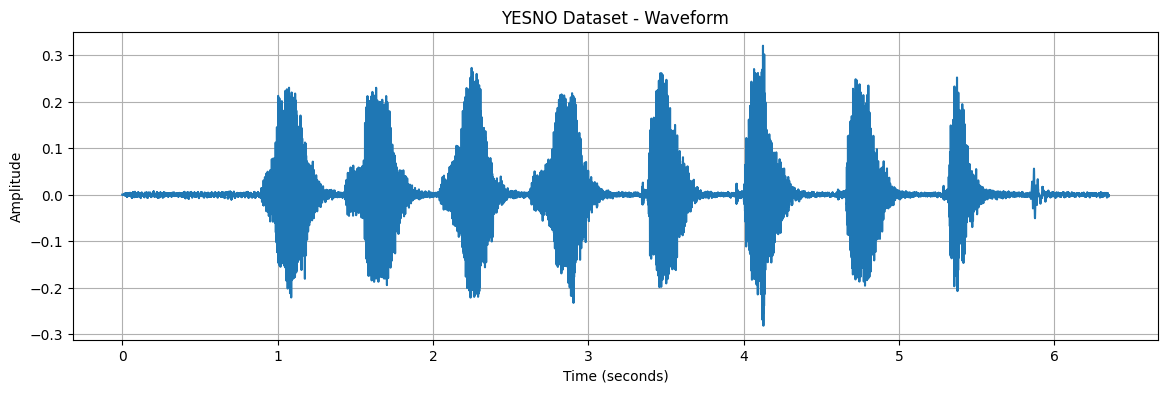

In [13]:

import numpy as np
import matplotlib.pyplot as plt

# Convert waveform to a NumPy array
audio = waveform[0].numpy()

# Create the time axis
time = np.arange(len(audio)) / sample_rate

# Plot the waveform
plt.figure(figsize=(14, 4))
plt.plot(time, audio)

plt.title("YESNO Dataset - Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


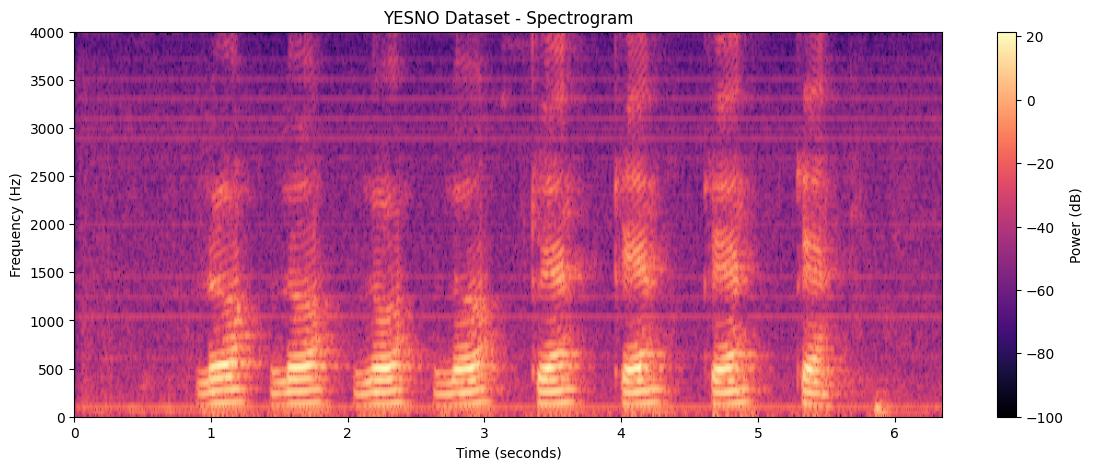

In [14]:

import torchaudio

# Compute spectrogram
spectrogram = torchaudio.transforms.Spectrogram(
    n_fft=256,
    hop_length=64,
    power=2
)(waveform)

# Convert power to decibels
spectrogram_db = torchaudio.transforms.AmplitudeToDB(
    stype="power"
)(spectrogram)

# Plot the spectrogram
plt.figure(figsize=(14, 5))

plt.imshow(
    spectrogram_db[0].numpy(),
    origin="lower",
    aspect="auto",
    extent=[
        0,
        waveform.shape[1] / sample_rate,
        0,
        sample_rate / 2
    ],
    cmap="magma"
)

plt.colorbar(label="Power (dB)")
plt.title("YESNO Dataset - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.show()


In [15]:

from IPython.display import Audio, display

# Play the first recording
display(Audio(waveform.numpy(), rate=sample_rate))


In [16]:

# Load the second recording
waveform2, sr2, labels2 = dataset[1]

print("Labels:", labels2)

# Play the recording
display(Audio(waveform2.numpy(), rate=sr2))


Labels: [0, 0, 0, 1, 0, 0, 0, 1]


## 4. Initial segmentation using short-time RMS

A short-time energy threshold detects candidate utterances. Binary morphology removes tiny events and joins short gaps. The eight detected events must be aligned with the eight original labels in order; identical counts alone do not guarantee alignment.


Detected segments: 8


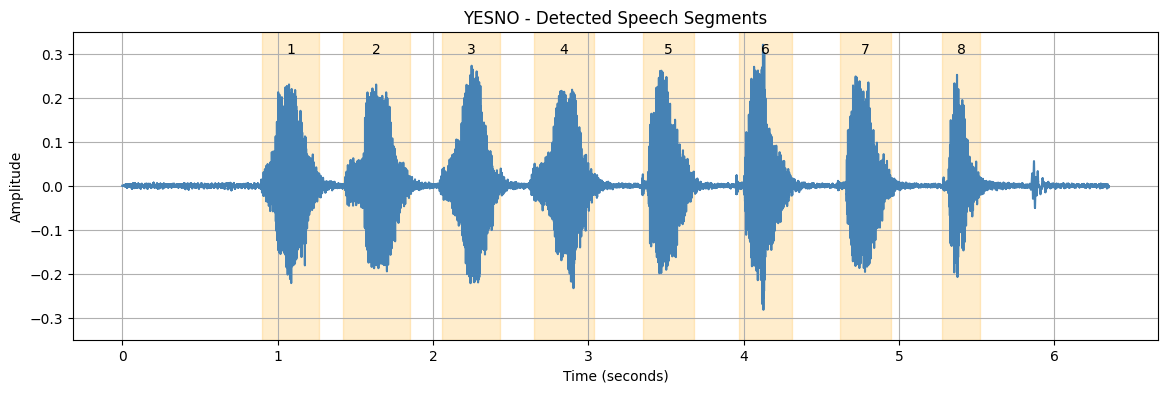

Segment boundaries:
Segment 1: 0.90s - 1.27s
Segment 2: 1.42s - 1.85s
Segment 3: 2.06s - 2.43s
Segment 4: 2.65s - 3.04s
Segment 5: 3.35s - 3.68s
Segment 6: 3.97s - 4.31s
Segment 7: 4.62s - 4.95s
Segment 8: 5.28s - 5.52s


In [17]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_closing, binary_opening, label

# First recording
audio = waveform[0].numpy()

# Calculate short-time RMS
frame_size = int(0.02 * sample_rate)  # 20 ms
hop_size = int(0.01 * sample_rate)    # 10 ms

rms = []
times = []

for start in range(0, len(audio) - frame_size + 1, hop_size):
    frame = audio[start:start + frame_size]
    rms.append(np.sqrt(np.mean(frame ** 2)))
    times.append((start + frame_size / 2) / sample_rate)

rms = np.array(rms)
times = np.array(times)

# Detect speech activity using an energy threshold
threshold = max(0.008, 0.15 * np.max(rms))
speech_mask = rms > threshold

# Join short gaps and remove tiny noise regions
speech_mask = binary_closing(speech_mask, structure=np.ones(8))
speech_mask = binary_opening(speech_mask, structure=np.ones(5))

regions, num_regions = label(speech_mask)

segments = []

for i in range(1, num_regions + 1):
    idx = np.where(regions == i)[0]
    start_time = max(0, times[idx[0]] - 0.04)
    end_time = min(len(audio) / sample_rate, times[idx[-1]] + 0.04)

    if end_time - start_time >= 0.12:
        segments.append((start_time, end_time))

print("Detected segments:", len(segments))

# Plot waveform and detected segments
time_axis = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, audio, color="steelblue")

for i, (start, end) in enumerate(segments):
    plt.axvspan(start, end, alpha=0.2, color="orange")
    plt.text((start + end) / 2, 0.3, str(i + 1),
             ha="center", fontsize=10)

plt.title("YESNO - Detected Speech Segments")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.ylim(-0.35, 0.35)
plt.grid(True)
plt.show()

print("Segment boundaries:")
for i, (start, end) in enumerate(segments):
    print(f"Segment {i+1}: {start:.2f}s - {end:.2f}s")


In [18]:

from IPython.display import Audio, display

# Listen to the 8 detected segments
for i, (start, end) in enumerate(segments):

    start_sample = int(start * sample_rate)
    end_sample = int(end * sample_rate)

    word_audio = audio[start_sample:end_sample]

    word_label = "Yes" if labels[i] == 1 else "No"

    print(f"Segment {i+1}: {word_label}")
    print(f"Time: {start:.2f} - {end:.2f} seconds")

    display(Audio(
        word_audio,
        rate=sample_rate,
        normalize=False
    ))


Segment 1: No
Time: 0.90 - 1.27 seconds


Segment 2: No
Time: 1.42 - 1.85 seconds


Segment 3: No
Time: 2.06 - 2.43 seconds


Segment 4: No
Time: 2.65 - 3.04 seconds


Segment 5: Yes
Time: 3.35 - 3.68 seconds


Segment 6: Yes
Time: 3.97 - 4.31 seconds


Segment 7: Yes
Time: 4.62 - 4.95 seconds


Segment 8: Yes
Time: 5.28 - 5.52 seconds


## 5. Apply segmentation across the entire dataset

The initial segmentation detects eight candidate events in 58 of 60 recordings. Inspect failed cases rather than silently assigning labels to mismatched segments.


In [19]:

import numpy as np
from scipy.ndimage import binary_closing, binary_opening, label

def split_yesno_recording(waveform, sample_rate):
    audio = waveform[0].numpy()

    frame_size = int(0.02 * sample_rate)
    hop_size = int(0.01 * sample_rate)

    rms = []
    times = []

    for start in range(0, len(audio) - frame_size + 1, hop_size):
        frame = audio[start:start + frame_size]

        rms.append(np.sqrt(np.mean(frame ** 2)))
        times.append((start + frame_size / 2) / sample_rate)

    rms = np.array(rms)
    times = np.array(times)

    threshold = max(0.008, 0.15 * np.max(rms))
    speech_mask = rms > threshold

    speech_mask = binary_closing(
        speech_mask, structure=np.ones(8)
    )

    speech_mask = binary_opening(
        speech_mask, structure=np.ones(5)
    )

    regions, num_regions = label(speech_mask)

    segments = []

    for i in range(1, num_regions + 1):
        idx = np.where(regions == i)[0]

        start_time = max(0, times[idx[0]] - 0.04)
        end_time = min(
            len(audio) / sample_rate,
            times[idx[-1]] + 0.04
        )

        if end_time - start_time >= 0.12:
            start_sample = int(start_time * sample_rate)
            end_sample = int(end_time * sample_rate)

            segments.append(
                audio[start_sample:end_sample]
            )

    return segments


# Test segmentation on all 60 recordings
successful = 0
failed = []

for i in range(len(dataset)):
    waveform_i, sr_i, labels_i = dataset[i]

    segments_i = split_yesno_recording(
        waveform_i, sr_i
    )

    if len(segments_i) == len(labels_i):
        successful += 1
    else:
        failed.append((i, len(segments_i)))

print("Total recordings:", len(dataset))
print("Successfully segmented:", successful)
print("Recordings needing review:", len(failed))
print("Failed recording details:", failed)


Total recordings: 60
Successfully segmented: 58
Recordings needing review: 2
Failed recording details: [(21, 7), (49, 7)]


## 6. Analyze segmentation errors and apply documented corrections

- **Recording index 21:** Seven audible utterances were observed, so this recording is excluded from the subsequent experiment. This does not establish which original label is missing.
- **Recording index 49:** The first detected event contains two audible words. It is manually split around 1.36 seconds based on visual and listening checks.

The boundaries below are manually reviewed approximations. This is a limitation to document in the results.


Recording index: 21
Expected words: 8
Labels: [0, 1, 0, 1, 0, 0, 0, 0]
Duration: 5.58 seconds


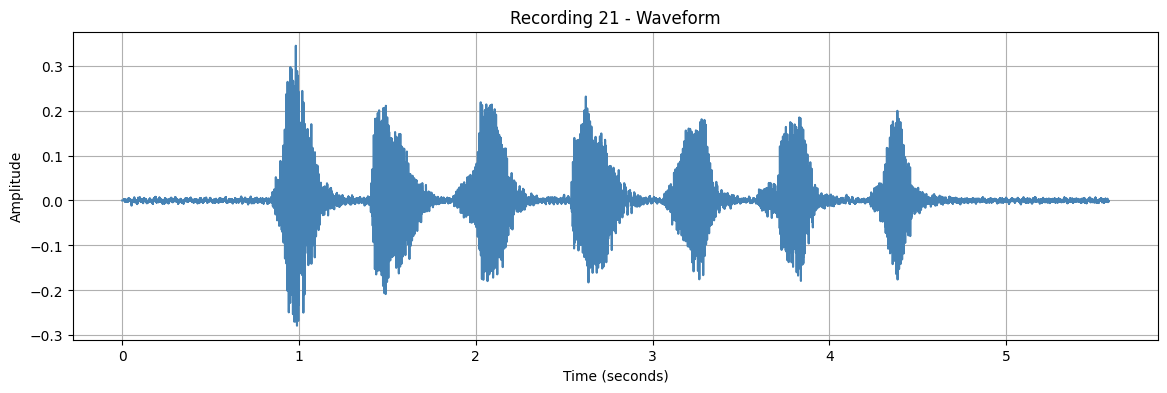

Listen to recording: 21


Recording index: 49
Expected words: 8
Labels: [1, 1, 0, 1, 1, 1, 1, 0]
Duration: 6.21 seconds


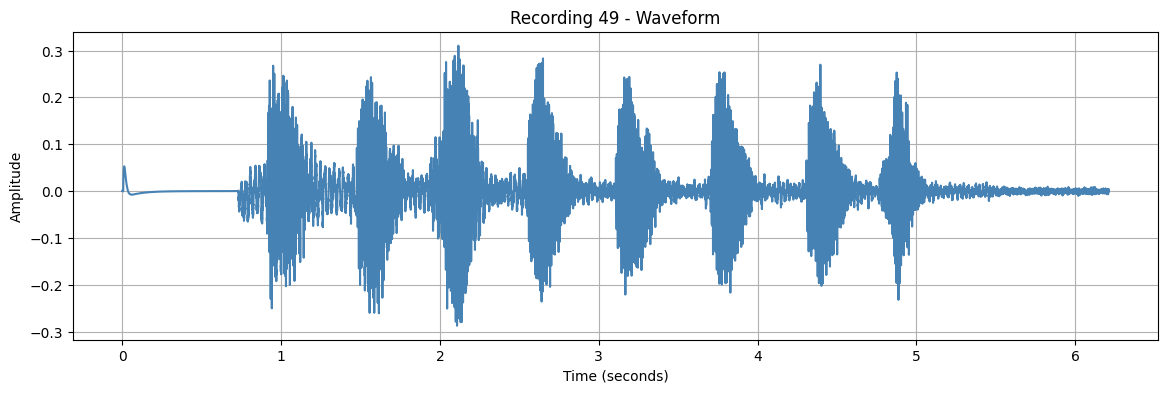

Listen to recording: 49


In [20]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Recordings that need review
failed_indices = [21, 49]

for idx in failed_indices:

    waveform_i, sr_i, labels_i = dataset[idx]
    audio_i = waveform_i[0].numpy()

    time_i = np.arange(len(audio_i)) / sr_i

    print("=" * 50)
    print("Recording index:", idx)
    print("Expected words:", len(labels_i))
    print("Labels:", labels_i)
    print("Duration:", len(audio_i) / sr_i, "seconds")

    # Plot waveform
    plt.figure(figsize=(14, 4))
    plt.plot(time_i, audio_i, color="steelblue")

    plt.title(f"Recording {idx} - Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

    # Listen to the full recording
    print("Listen to recording:", idx)
    display(Audio(audio_i, rate=sr_i))


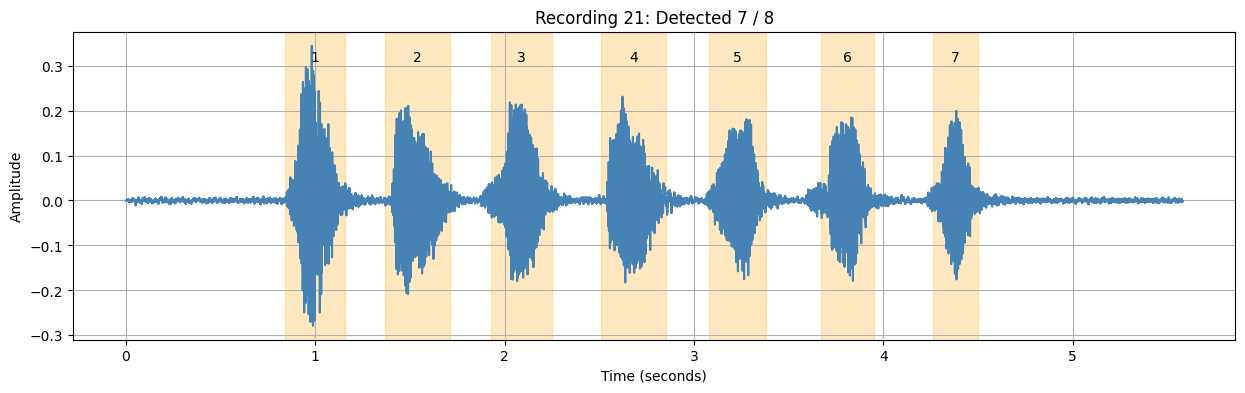

Detected segments:
1: 0.84 - 1.16 seconds
2: 1.37 - 1.71 seconds
3: 1.93 - 2.25 seconds
4: 2.51 - 2.85 seconds
5: 3.08 - 3.38 seconds
6: 3.67 - 3.95 seconds
7: 4.26 - 4.50 seconds


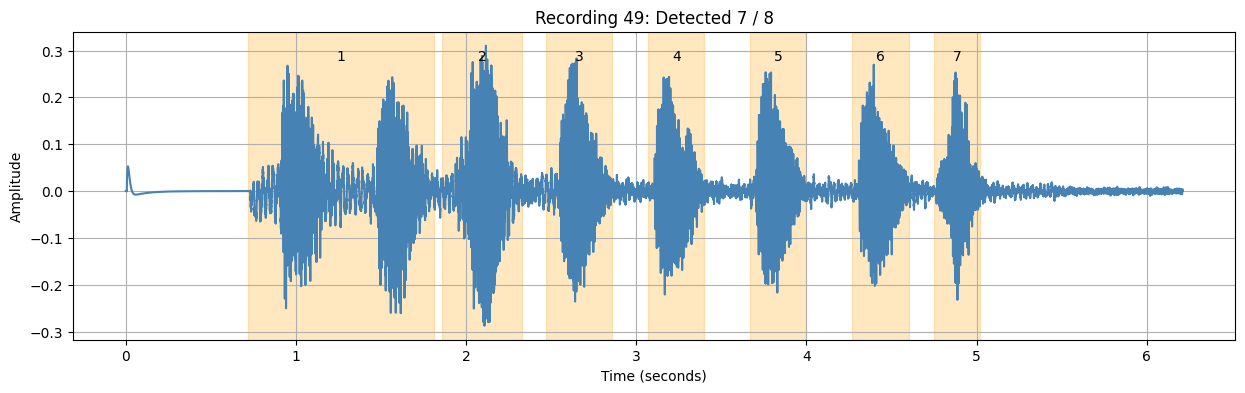

Detected segments:
1: 0.72 - 1.81 seconds
2: 1.86 - 2.33 seconds
3: 2.47 - 2.86 seconds
4: 3.07 - 3.40 seconds
5: 3.67 - 4.00 seconds
6: 4.27 - 4.60 seconds
7: 4.75 - 5.02 seconds


In [21]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_closing, binary_opening, label

def show_detected_regions(index):
    waveform_i, sr_i, labels_i = dataset[index]
    audio_i = waveform_i[0].numpy()

    frame_size = int(0.02 * sr_i)
    hop_size = int(0.01 * sr_i)

    rms = []
    times = []

    for start in range(0, len(audio_i) - frame_size + 1, hop_size):
        frame = audio_i[start:start + frame_size]
        rms.append(np.sqrt(np.mean(frame ** 2)))
        times.append((start + frame_size / 2) / sr_i)

    rms = np.array(rms)
    times = np.array(times)

    threshold = max(0.008, 0.15 * np.max(rms))
    mask = rms > threshold

    mask = binary_closing(mask, structure=np.ones(8))
    mask = binary_opening(mask, structure=np.ones(5))

    regions, count = label(mask)
    segments = []

    for i in range(1, count + 1):
        positions = np.where(regions == i)[0]

        start = max(0, times[positions[0]] - 0.04)
        end = min(len(audio_i) / sr_i,
                  times[positions[-1]] + 0.04)

        if end - start >= 0.12:
            segments.append((start, end))

    t = np.arange(len(audio_i)) / sr_i

    plt.figure(figsize=(15, 4))
    plt.plot(t, audio_i, color="steelblue")

    for i, (start, end) in enumerate(segments):
        plt.axvspan(start, end, color="orange", alpha=0.25)
        plt.text((start + end) / 2,
                 max(audio_i) * 0.9,
                 str(i + 1),
                 ha="center")

    plt.title(f"Recording {index}: Detected {len(segments)} / 8")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

    print("Detected segments:")
    for i, (start, end) in enumerate(segments):
        print(f"{i+1}: {start:.2f} - {end:.2f} seconds")


show_detected_regions(21)
show_detected_regions(49)


In [22]:

from IPython.display import Audio, display

wave49, sr49, labels49 = dataset[49]
audio49 = wave49[0].numpy()

# Proposed split of merged first segment
test_segments = [
    (0.72, 1.36),
    (1.36, 1.81)
]

for i, (start, end) in enumerate(test_segments):
    segment = audio49[
        int(start * sr49):int(end * sr49)
    ]

    print(f"Candidate word {i+1}")
    print(f"Time: {start:.2f} - {end:.2f} seconds")

    display(Audio(segment, rate=sr49))


Candidate word 1
Time: 0.72 - 1.36 seconds


Candidate word 2
Time: 1.36 - 1.81 seconds


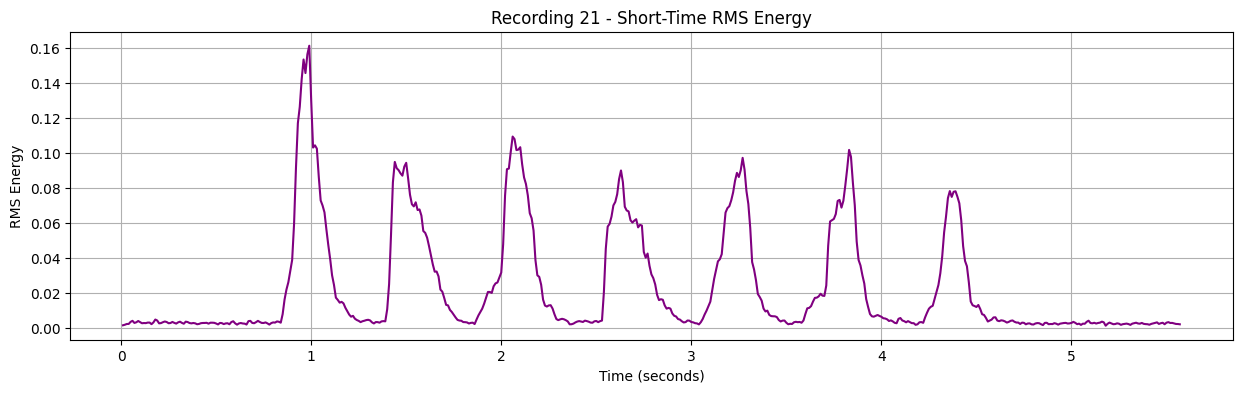

Recording 21 labels: [0, 1, 0, 1, 0, 0, 0, 0]
Expected words: 8


In [23]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

wave21, sr21, labels21 = dataset[21]
audio21 = wave21[0].numpy()

frame_size = int(0.02 * sr21)
hop_size = int(0.01 * sr21)

rms21 = []
times21 = []

for start in range(0, len(audio21) - frame_size + 1, hop_size):
    frame = audio21[start:start + frame_size]

    rms21.append(np.sqrt(np.mean(frame ** 2)))
    times21.append((start + frame_size / 2) / sr21)

rms21 = np.array(rms21)
times21 = np.array(times21)

plt.figure(figsize=(15, 4))
plt.plot(times21, rms21, color="purple")

plt.title("Recording 21 - Short-Time RMS Energy")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS Energy")
plt.grid(True)
plt.show()

print("Recording 21 labels:", labels21)
print("Expected words:", len(labels21))

display(Audio(audio21, rate=sr21))


In [24]:

# Corrected segmentation boundaries for recording 49

corrected_49 = [
    (0.72, 1.36),
    (1.36, 1.81),
    (1.86, 2.33),
    (2.47, 2.86),
    (3.07, 3.40),
    (3.67, 4.00),
    (4.27, 4.60),
    (4.75, 5.02)
]

wave49, sr49, labels49 = dataset[49]
audio49 = wave49[0].numpy()

segments_49 = []

for start, end in corrected_49:
    segment = audio49[
        int(start * sr49):int(end * sr49)
    ]
    segments_49.append(segment)

print("Recording 49 segments:", len(segments_49))
print("Recording 49 labels:", labels49)


Recording 49 segments: 8
Recording 49 labels: [1, 1, 0, 1, 1, 1, 1, 0]


## 7. Construct the labeled word-segment dataset

The resulting working set contains **472 segments from 59 recordings**, with **249 Yes** and **223 No** labels. Record index 21 is excluded. Record index 49 uses corrected boundaries.


In [25]:

import numpy as np
from collections import Counter

X_audio = []
y_labels = []
recording_ids = []

for idx in range(len(dataset)):

    if idx == 21:
        continue

    waveform_i, sr_i, labels_i = dataset[idx]

    if idx == 49:
        word_segments = segments_49
    else:
        word_segments = split_yesno_recording(
            waveform_i, sr_i
        )

    # Include only recordings with 8 detected words
    if len(word_segments) != len(labels_i):
        print("Skipped recording:", idx)
        continue

    for segment, word_label in zip(word_segments, labels_i):

        X_audio.append(np.asarray(segment, dtype=np.float32))
        y_labels.append(int(word_label))
        recording_ids.append(idx)

print("Total audio segments:", len(X_audio))
print("Total labels:", len(y_labels))
print("Class distribution:", Counter(y_labels))
print("Recording count:", len(set(recording_ids)))


Total audio segments: 472
Total labels: 472
Class distribution: Counter({1: 249, 0: 223})
Recording count: 59


## 8. Group-aware train/test split

Split by **source recording ID**, not randomly by word segment, to avoid putting utterances from the same original recording in both partitions. The observed split has 376 training segments and 96 test segments, with zero shared recordings.

**Limitation:** All recordings originate from a single speaker. Recording-level separation therefore does **not** establish generalization to unseen speakers.


In [26]:

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

# Convert labels and recording IDs to arrays
y = np.array(y_labels)
groups = np.array(recording_ids)

# Split by original recording
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_audio, y, groups)
)

print("Training segments:", len(train_idx))
print("Testing segments:", len(test_idx))

print("Training labels:", Counter(y[train_idx]))
print("Testing labels:", Counter(y[test_idx]))

# Check for recording overlap
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print("Shared recordings:",
      train_groups.intersection(test_groups))


Training segments: 376
Testing segments: 96
Training labels: Counter({np.int64(1): 196, np.int64(0): 180})
Testing labels: Counter({np.int64(1): 53, np.int64(0): 43})
Shared recordings: set()


## 9. MFCC feature extraction

Extract 13 MFCC coefficients per short audio frame. For each coefficient, calculate its time-mean and time-standard deviation, obtaining **26 fixed-length numerical features per word**. The reported feature matrix shape is `(472, 26)`.


In [27]:

import torch
import torchaudio
import numpy as np

# Create the MFCC extractor
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=8000,
    n_mfcc=13,
    melkwargs={
        "n_fft": 256,
        "hop_length": 80,
        "n_mels": 40
    }
)

def extract_mfcc_features(audio_segment):

    # Convert NumPy audio to PyTorch tensor
    audio_tensor = torch.tensor(
        audio_segment,
        dtype=torch.float32
    ).unsqueeze(0)

    # Extract MFCC coefficients
    mfcc = mfcc_transform(audio_tensor)

    # Remove channel dimension
    mfcc = mfcc.squeeze(0).numpy()

    # Calculate mean and standard deviation
    mean_features = np.mean(mfcc, axis=1)
    std_features = np.std(mfcc, axis=1)

    # Combine into one feature vector
    features = np.concatenate([
        mean_features,
        std_features
    ])

    return features


# Extract features from all segments
X_features = np.array([
    extract_mfcc_features(segment)
    for segment in X_audio
])

print("MFCC feature matrix:", X_features.shape)
print("Features per segment:", X_features.shape[1])
print("First segment features:")
print(X_features[0])


MFCC feature matrix: (472, 26)
Features per segment: 26
First segment features:
[-116.646164    82.57278     -3.029162     1.5371006  -20.715979
  -11.384873    -7.840177     8.039554     4.3094144  -10.888424
    0.7336296   -2.7731853   -5.731577    36.261692     8.576822
   17.80145     11.71227     13.907474    14.615196    10.269557
    9.868779     6.6310396    9.8086815    3.11782      5.2746572
    5.3713512]


## 10. Classifier 1 — Support Vector Machine

Use an RBF-kernel SVM with standardized features. The scaler is fitted only on the training partition by the scikit-learn pipeline.


SVM Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



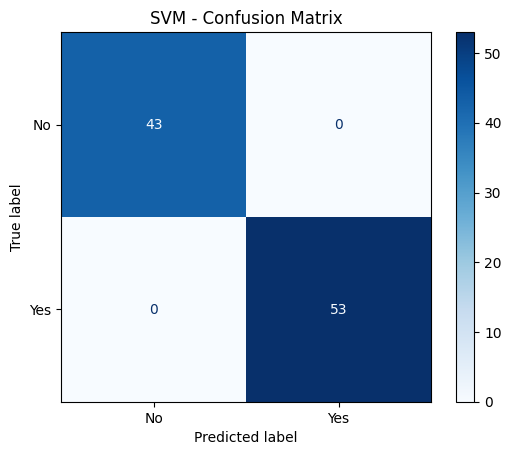

In [28]:

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 1: Prepare training and testing data
X_train = X_features[train_idx]
X_test = X_features[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Step 2: Create SVM model with scaling
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        random_state=42
    ))
])

# Step 3: Train model
svm_model.fit(X_train, y_train)

# Step 4: Predict test labels
y_pred_svm = svm_model.predict(X_test)

# Step 5: Evaluate model
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(accuracy_svm * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["No", "Yes"],
    zero_division=0
))

# Step 6: Confusion matrix
cm = confusion_matrix(
    y_test, y_pred_svm, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("SVM - Confusion Matrix")
plt.show()


## 11. Classifier 2 — K-Nearest Neighbors

Use five neighbors after standardization. The test partition remains identical for all four algorithms.


KNN Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



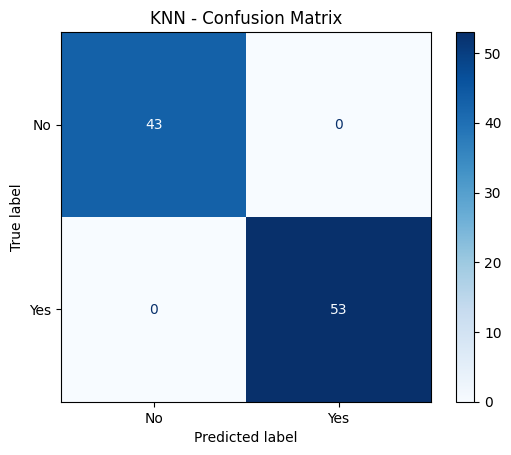

In [29]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create KNN model
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train KNN
knn_model.fit(X_train, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test)

# Evaluate
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", round(accuracy_knn * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

# Confusion matrix
cm_knn = confusion_matrix(
    y_test, y_pred_knn, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("KNN - Confusion Matrix")
plt.show()


## 12. Classifier 3 — Random Forest

Use 100 trees. Tree models do not require feature scaling for this experiment.


Random Forest Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



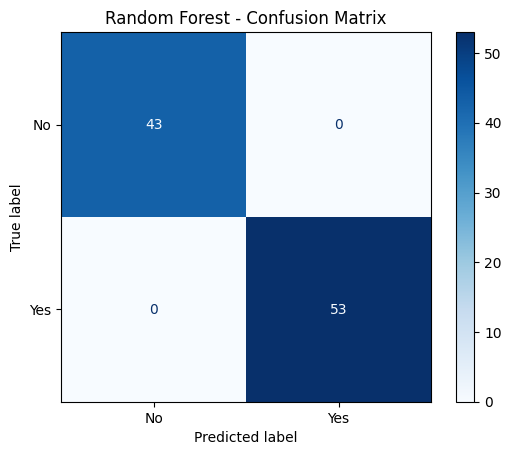

In [30]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 1: Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Step 2: Train model
rf_model.fit(X_train, y_train)

# Step 3: Predict test labels
y_pred_rf = rf_model.predict(X_test)

# Step 4: Evaluate model
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(
    "Random Forest Accuracy:",
    round(accuracy_rf * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No", "Yes"],
    zero_division=0
))

# Step 5: Confusion Matrix
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()


## 13. Classifier 4 — Neural Network (MLP)

Use hidden layers with 64 and 32 units and early stopping. **Methodological caution:** scikit-learn's internal early-stopping validation partition does not preserve source-recording groups. The external train/test and grouped CV splits still enforce recording separation; a fully group-aware internal validation scheme would be preferable for future experiments.


Neural Network Accuracy: 96.88 %

Classification Report:
              precision    recall  f1-score   support

          No       0.93      1.00      0.97        43
         Yes       1.00      0.94      0.97        53

    accuracy                           0.97        96
   macro avg       0.97      0.97      0.97        96
weighted avg       0.97      0.97      0.97        96



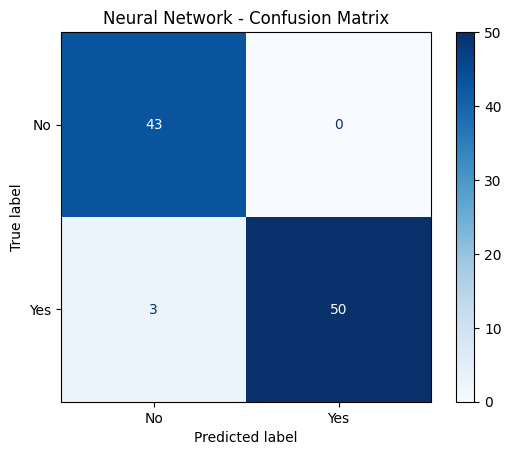

In [31]:

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 1: Create Neural Network
nn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=42
    ))
])

# Step 2: Train Neural Network
nn_model.fit(X_train, y_train)

# Step 3: Predict
y_pred_nn = nn_model.predict(X_test)

# Step 4: Evaluate
accuracy_nn = accuracy_score(y_test, y_pred_nn)

print(
    "Neural Network Accuracy:",
    round(accuracy_nn * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nn,
    target_names=["No", "Yes"],
    zero_division=0
))

# Step 5: Confusion Matrix
cm_nn = confusion_matrix(
    y_test,
    y_pred_nn,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Neural Network - Confusion Matrix")
plt.show()


## 14. Five-fold grouped cross-validation

Use `StratifiedGroupKFold` to keep utterances from each original recording together within a fold. Report both the mean and standard deviation of accuracy. The reported numbers are based on the stored outputs in this notebook.


In [32]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.base import clone

models = {
    "SVM": svm_model,
    "KNN": knn_model,
    "Random Forest": rf_model,
    "Neural Network": nn_model
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        clone(model),
        X_features,
        y,
        groups=groups,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1_macro"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean Accuracy (%)":
            np.mean(scores["test_accuracy"]) * 100,
        "Std Accuracy (%)":
            np.std(scores["test_accuracy"]) * 100,
        "Mean F1":
            np.mean(scores["test_f1"])
    })

cv_results = pd.DataFrame(results)

print("5-Fold Group Cross-Validation Results")
print(cv_results.round(4).to_string(index=False))


5-Fold Group Cross-Validation Results
         Model  Mean Accuracy (%)  Std Accuracy (%)  Mean F1
           SVM           100.0000            0.0000   1.0000
           KNN           100.0000            0.0000   1.0000
 Random Forest           100.0000            0.0000   1.0000
Neural Network            97.2159            1.8822   0.9721


## 15. Experimental results and discussion

### Held-out test set (96 speech segments)

| Classifier | Accuracy | Correct predictions | Errors |
|---|---:|---:|---:|
| SVM | 100.00% | 96 | 0 |
| KNN | 100.00% | 96 | 0 |
| Random Forest | 100.00% | 96 | 0 |
| MLP Neural Network | 96.88% | 93 | 3 |

The MLP confusion matrix shows **43/43 No** items and **50/53 Yes** items correctly classified; three Yes items were predicted as No. The other classifiers made no errors on this particular test split.

### Five-fold grouped cross-validation

| Classifier | Mean accuracy (%) | Std. accuracy (percentage points) | Mean macro F1 |
|---|---:|---:|---:|
| SVM | 100.0000 | 0.0000 | 1.0000 |
| KNN | 100.0000 | 0.0000 | 1.0000 |
| Random Forest | 100.0000 | 0.0000 | 1.0000 |
| MLP Neural Network | 97.2159 | 1.8822 | 0.9721 |

These are the actual stored results of the reported run. The perfect scores should **not** be interpreted as evidence of universally error-free speech recognition.

## 16. Limitations and conclusion

The experiment demonstrates effective binary classification of the available YESNO recordings with compact MFCC features. The SVM, KNN, and Random Forest reached perfect scores on the chosen held-out recordings and the reported grouped folds, while the MLP performed slightly below them.

**Limitations:** The dataset is small and single-speaker; segmentation relies on RMS heuristics and manual review; index 21 was excluded; index 49 was corrected; and the MLP's internal early-stopping split is not group-aware. Repeating the experiment with different speakers, additional noise conditions, and independently validated word boundaries would provide stronger evidence of generalization.

**Conclusion:** Four required classifiers have been trained and evaluated, and the results favor the classical classifiers for this specific dataset and experimental setup. The results are not a claim that classical models always outperform neural networks.

**Reproducibility:** Preserve the exact package versions, random seeds, dataset preprocessing, and printed outputs when submitting the notebook. Run all cells from a clean session before final submission.
